# Challenge 1 – Segmentation and counting
**Group:** (names) &nbsp; **N =** (2 or 3)

Pipeline: pre-processing → *segmentation method* → **shared** post-processing → label image + count → evaluation.
All methods go through the same post-processing, so the comparison isolates the segmentation step.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import measure, morphology, segmentation
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier

SEED = 0
np.random.seed(SEED)

IN, ANN, OUT = Path("inputs"), Path("annotations"), Path("outputs/c1")
OUT.mkdir(parents=True, exist_ok=True)
EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
paths = sorted(p for p in IN.iterdir() if p.suffix.lower() in EXT)
print(len(paths), "images found in", IN)

# ---- parameters (justify every one in the report) ----
MAX_SIDE       = 1200    # working resolution (longest side, px)
MIN_AREA_FRAC  = 3e-4    # smallest accepted part, as fraction of image area
OPEN_R, CLOSE_R = 1, 2   # morphology radii (px)
HOLE_FILL      = 35      # holes < this (px, at 1200 px) are filled: thread gaps measured 17-27 px, smallest nut bores 54-120 px
SPLIT_TOUCHING = False   # watershed split of touching parts (ablate it!)
TEST_FRAC      = 0.5     # share of annotated images held out for evaluation
PLANE_M1 = "b"           # CIELAB b*: wood is uniformly bright, every finish is darker (see plane study)
PLANE_M2 = "b"           # plane for adaptive threshold

Matplotlib is building the font cache; this may take a moment.


10 images found in inputs


## 1. Data loading and annotations

In [2]:
def prep(p):
    img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]; s = MAX_SIDE / max(h, w)
    return cv2.resize(img, (int(w*s), int(h*s)), interpolation=cv2.INTER_AREA) if s < 1 else img

def load_gt(p, shape):
    f = ANN / f"{p.stem}_labels.png"
    if not f.exists(): return None
    g = cv2.imread(str(f), cv2.IMREAD_UNCHANGED)
    if g.ndim == 3: g = g[..., 0]
    return cv2.resize(g, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST).astype(np.int32)

annotated = [p for p in paths if (ANN / f"{p.stem}_labels.png").exists()]
# split by SOURCE image: augmented copies (<stem>__augN) must stay on the same side as their original
src = lambda p: p.stem.split("__aug")[0]
sources = sorted({src(p) for p in annotated})
order = np.random.RandomState(SEED).permutation(len(sources))
n_test = max(1, int(round(TEST_FRAC * len(sources)))) if sources else 0
test_src = {sources[i] for i in order[:n_test]}
test_set  = [p for p in annotated if src(p) in test_src]
train_set = [p for p in annotated if src(p) not in test_src] or test_set   # fallback if very few annotations
print(f"{len(annotated)} annotated images from {len(sources)} sources | train (pixel classifier only): {len(train_set)} | test: {len(test_set)}")

10 annotated images from 10 sources | train (pixel classifier only): 5 | test: 5


## 2. Colour planes
**Question: which colour plane separates golden screws, black screws and silver nuts from the wood?**
Below: Otsu on every plane (minority class = parts), ranked by mean IoU on the test images.

In [3]:
def planes(img):
    s = cv2.medianBlur(img, 5)
    hsv = cv2.cvtColor(s, cv2.COLOR_RGB2HSV).astype(np.float32)
    lab = cv2.cvtColor(s, cv2.COLOR_RGB2LAB).astype(np.float32)
    f = lambda a: a.astype(np.float32)
    return {"R": f(s[...,0]), "G": f(s[...,1]), "B": f(s[...,2]),
            "S": hsv[...,1], "V": hsv[...,2],
            "L": lab[...,0], "a": lab[...,1], "b": lab[...,2]}

def to8(x): return cv2.normalize(x, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

def otsu_mask(x):
    _, m = cv2.threshold(to8(x), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = m > 0
    return m if m.mean() < 0.5 else ~m          # parts are the minority class

## 3. Shared post-processing, label image and metrics
Nut bores must **not** be filled (the hole is the key feature for Challenge 2); only tiny holes (noise) are closed.

In [4]:
def postprocess(mask, split=None):
    split = SPLIT_TOUCHING if split is None else split
    H, W = mask.shape
    min_area = max(20, int(MIN_AREA_FRAC * H * W))
    m = mask.astype(np.uint8)
    k = lambda r: cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*r+1, 2*r+1))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN,  k(OPEN_R))
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k(CLOSE_R))
    # fill only tiny holes (thread gaps, noise); nut bores are larger
    n, l, st, _ = cv2.connectedComponentsWithStats(1 - m, connectivity=4)
    small = [i for i in range(1, n) if st[i, cv2.CC_STAT_AREA] < HOLE_FILL]
    m[np.isin(l, small)] = 1
    # remove small objects
    n, l, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    keep = [i for i in range(1, n) if st[i, cv2.CC_STAT_AREA] >= min_area]
    m = np.isin(l, keep)
    if split:
        d = cv2.GaussianBlur(ndi.distance_transform_edt(m).astype(np.float32), (0, 0), 1.5)
        markers = measure.label(morphology.h_maxima(d, 2.0))
        return segmentation.watershed(-d, markers, mask=m).astype(np.int32)
    return measure.label(m, connectivity=2).astype(np.int32)

def pixel_metrics(pred, gt):
    p, g = pred > 0, gt > 0
    tp, fp, fn, tn = (p&g).sum(), (p&~g).sum(), (~p&g).sum(), (~p&~g).sum()
    return dict(precision=tp/max(tp+fp,1), recall=tp/max(tp+fn,1),
                accuracy=(tp+tn)/p.size, iou=tp/max(tp+fp+fn,1))

def instance_metrics(pred, gt):
    P, G = np.unique(pred[pred>0]), np.unique(gt[gt>0])
    ga = {g:int((gt==g).sum()) for g in G};  pa = {p:int((pred==p).sum()) for p in P}
    m = (pred>0) & (gt>0)
    if m.any():
        pairs, cnt = np.unique(np.stack([gt[m], pred[m]], 1), axis=0, return_counts=True)
    else:
        pairs, cnt = np.zeros((0,2), int), np.zeros(0, int)
    matched = {p for (g,p),c in zip(pairs,cnt) if c/(ga[g]+pa[p]-c) >= 0.5}
    tp = len(matched)
    merges = sum(sum(c/ga[g] >= .5 for (g,pp),c in zip(pairs,cnt) if pp==p) >= 2 for p in P)
    splits = sum(sum(c/pa[p] >= .5 for (gg,p),c in zip(pairs,cnt) if gg==g) >= 2 for g in G)
    return dict(n_gt=len(G), n_pred=len(P), inst_tp=tp, inst_fp=len(P)-tp, inst_fn=len(G)-tp,
                merges=int(merges), splits=int(splits), count_err=len(P)-len(G))

In [5]:
# ---- plane study (Otsu on each plane) ----
rows = []
for p in test_set:
    img = prep(p); gt = load_gt(p, img.shape)
    for name, x in planes(img).items():
        rows.append(dict(plane=name, **pixel_metrics(postprocess(otsu_mask(x)), gt)))
if rows:
    plane_tbl = pd.DataFrame(rows).groupby("plane").mean().sort_values("iou", ascending=False)
    plane_tbl.round(3).to_csv(OUT / "plane_study.csv"); display(plane_tbl.round(3))
else:
    print("No annotated images: plane study skipped.")

,precision,recall,accuracy,iou
plane,,,,
b,0.965,0.966,0.997,0.933
R,0.522,0.826,0.886,0.495
V,0.522,0.822,0.885,0.494
S,0.623,0.735,0.845,0.416
B,0.259,0.777,0.669,0.154
L,0.152,0.824,0.788,0.150
G,0.098,0.824,0.689,0.097
a,0.079,0.690,0.612,0.078


## 4. Segmentation methods (different families)
| # | Method | Family |
|---|--------|--------|
| 1 | Global Otsu on one colour plane | histogram thresholding |
| 2 | Local (adaptive) threshold on one plane | adaptive thresholding |
| 3 | k-means (k=2) on CIELAB b* | clustering |
| 4 | Random forest on per-pixel features | statistical pixel classification (trained on train images) |

Add more (e.g. watershed, edge-based) if N = 3. **What breaks a global threshold?** Look at stains, dark chips, highlights on nuts.

In [6]:
def seg_otsu(img):
    return otsu_mask(planes(img)[PLANE_M1])

def seg_adaptive(img, frac=0.12, C=25):
    x = to8(planes(img)[PLANE_M2]).astype(np.float32)
    ref = otsu_mask(x)                                   # only used to decide polarity
    sign = 1 if ref.any() and x[ref].mean() > x[~ref].mean() else -1
    bs = int(frac * min(x.shape)); bs += 1 - bs % 2
    mu = cv2.GaussianBlur(x, (0, 0), bs / 6)
    return sign * (x - mu) > C

def seg_kmeans(img, k=2, margin=15):
    # k-means on CIELAB b* (the plane found best in the plane study); fg = clusters clearly darker than the wood cluster
    b = cv2.cvtColor(cv2.medianBlur(img, 5), cv2.COLOR_RGB2LAB)[..., 2].astype(np.float32).reshape(-1, 1)
    idx = np.random.RandomState(SEED).choice(len(b), min(50000, len(b)), replace=False)
    km = KMeans(k, n_init=4, random_state=SEED).fit(b[idx])
    lbl = km.predict(b); c = km.cluster_centers_[:, 0]
    bg = np.argmax(np.bincount(lbl, minlength=k))        # wood = largest cluster
    return np.isin(lbl, [i for i in range(k) if c[i] < c[bg] - margin]).reshape(img.shape[:2])

def pix_features(img):
    pl = planes(img); L = pl["L"]
    mu = cv2.blur(L, (7, 7)); sd = np.sqrt(np.maximum(cv2.blur(L*L, (7, 7)) - mu*mu, 0))
    return np.dstack([pl["L"], pl["a"], pl["b"], pl["S"], pl["V"], sd]).reshape(-1, 6)

clf = None
if train_set:
    X, y, r = [], [], np.random.RandomState(SEED)
    for p in train_set:
        img = prep(p); gt = load_gt(p, img.shape); F = pix_features(img); t = (gt > 0).ravel()
        i = r.choice(len(t), min(20000, len(t)), replace=False); X.append(F[i]); y.append(t[i])
    clf = RandomForestClassifier(100, max_depth=14, class_weight="balanced",
                                 random_state=SEED, n_jobs=-1).fit(np.vstack(X), np.concatenate(y))

def seg_pixclf(img):
    return clf.predict(pix_features(img)).reshape(img.shape[:2]).astype(bool)

METHODS = {"otsu": seg_otsu, "adaptive": seg_adaptive, "kmeans": seg_kmeans}
if clf is not None: METHODS["pixel_rf"] = seg_pixclf
print(list(METHODS))

['otsu', 'adaptive', 'kmeans', 'pixel_rf']


## 5. Run on every image in `inputs/`, save label images and counts

In [7]:
counts, rows = [], []
cache = {}
for p in paths:
    img = prep(p); gt = load_gt(p, img.shape)
    for name, fn in METHODS.items():
        lab = postprocess(fn(img))
        (OUT / name).mkdir(exist_ok=True)
        cv2.imwrite(str(OUT / name / f"{p.stem}_labels.png"), lab.astype(np.uint16))
        counts.append(dict(image=p.name, method=name, n_parts=int(lab.max())))
        if p in test_set:
            rows.append(dict(image=p.name, source=src(p), aug=("__aug" in p.stem), method=name, **pixel_metrics(lab, gt), **instance_metrics(lab, gt)))
            cache[(p.name, name)] = lab
pd.DataFrame(counts).to_csv(OUT / "counts.csv", index=False)
res = pd.DataFrame(rows); res.to_csv(OUT / "metrics_per_image.csv", index=False)
print("done")

done


## 6. Results (test images only)
Report mean ± std over images, not just the mean. Pixel metrics + instance metrics (merges, splits, false positives, count error).

In [8]:
if len(res):
    summ = res.drop(columns=["image","source"]).groupby(["aug","method"]).agg(["mean", "std"]).round(3)
    summ.to_csv(OUT / "summary.csv"); display(summ)
    cnt = res.assign(abs_count_err=res.count_err.abs()).groupby(["aug","method"])[["abs_count_err","merges","splits","inst_fp","inst_fn"]].sum()
    display(cnt)

precision        recall        accuracy           iou         \
                    mean    std   mean    std     mean    std   mean    std   
aug   method                                                                  
False adaptive     0.957  0.026  0.798  0.073    0.990  0.004  0.768  0.052   
      kmeans       0.968  0.007  0.957  0.013    0.997  0.001  0.927  0.010   
      otsu         0.965  0.004  0.966  0.003    0.997  0.001  0.933  0.007   
      pixel_rf     0.927  0.029  0.975  0.020    0.996  0.001  0.905  0.012   

               n_gt         ... inst_fp        inst_fn        merges       \
               mean    std  ...    mean    std    mean    std   mean  std   
aug   method                ...                                             
False adaptive  8.6  0.894  ...     1.8  0.837     0.2  0.447    0.0  0.0   
      kmeans    8.6  0.894  ...     0.0  0.000     0.0  0.000    0.0  0.0   
      otsu      8.6  0.894  ...     0.0  0.000     0.0  0.000    0.0  0.0   
      pixel_rf  8.6  0.894  ...     0.2  0.447     0.0  0.000    0.0  0.0   

               splits        count_err         
                 mean    std      mean    std  
aug   method                                   
False adaptive    0.2  0.447       1.6  0.894  
      kmeans      0.0  0.000       0.0  0.000  
      otsu        0.0  0.000       0.0  0.000  
      pixel_rf    0.0  0.000       0.2  0.447  

[4 rows x 24 columns]

abs_count_err  merges  splits  inst_fp  inst_fn
aug   method                                                   
False adaptive              8       0       1        9        1
      kmeans                0       0       0        0        0
      otsu                  0       0       0        0        0
      pixel_rf              1       0       0        1        0

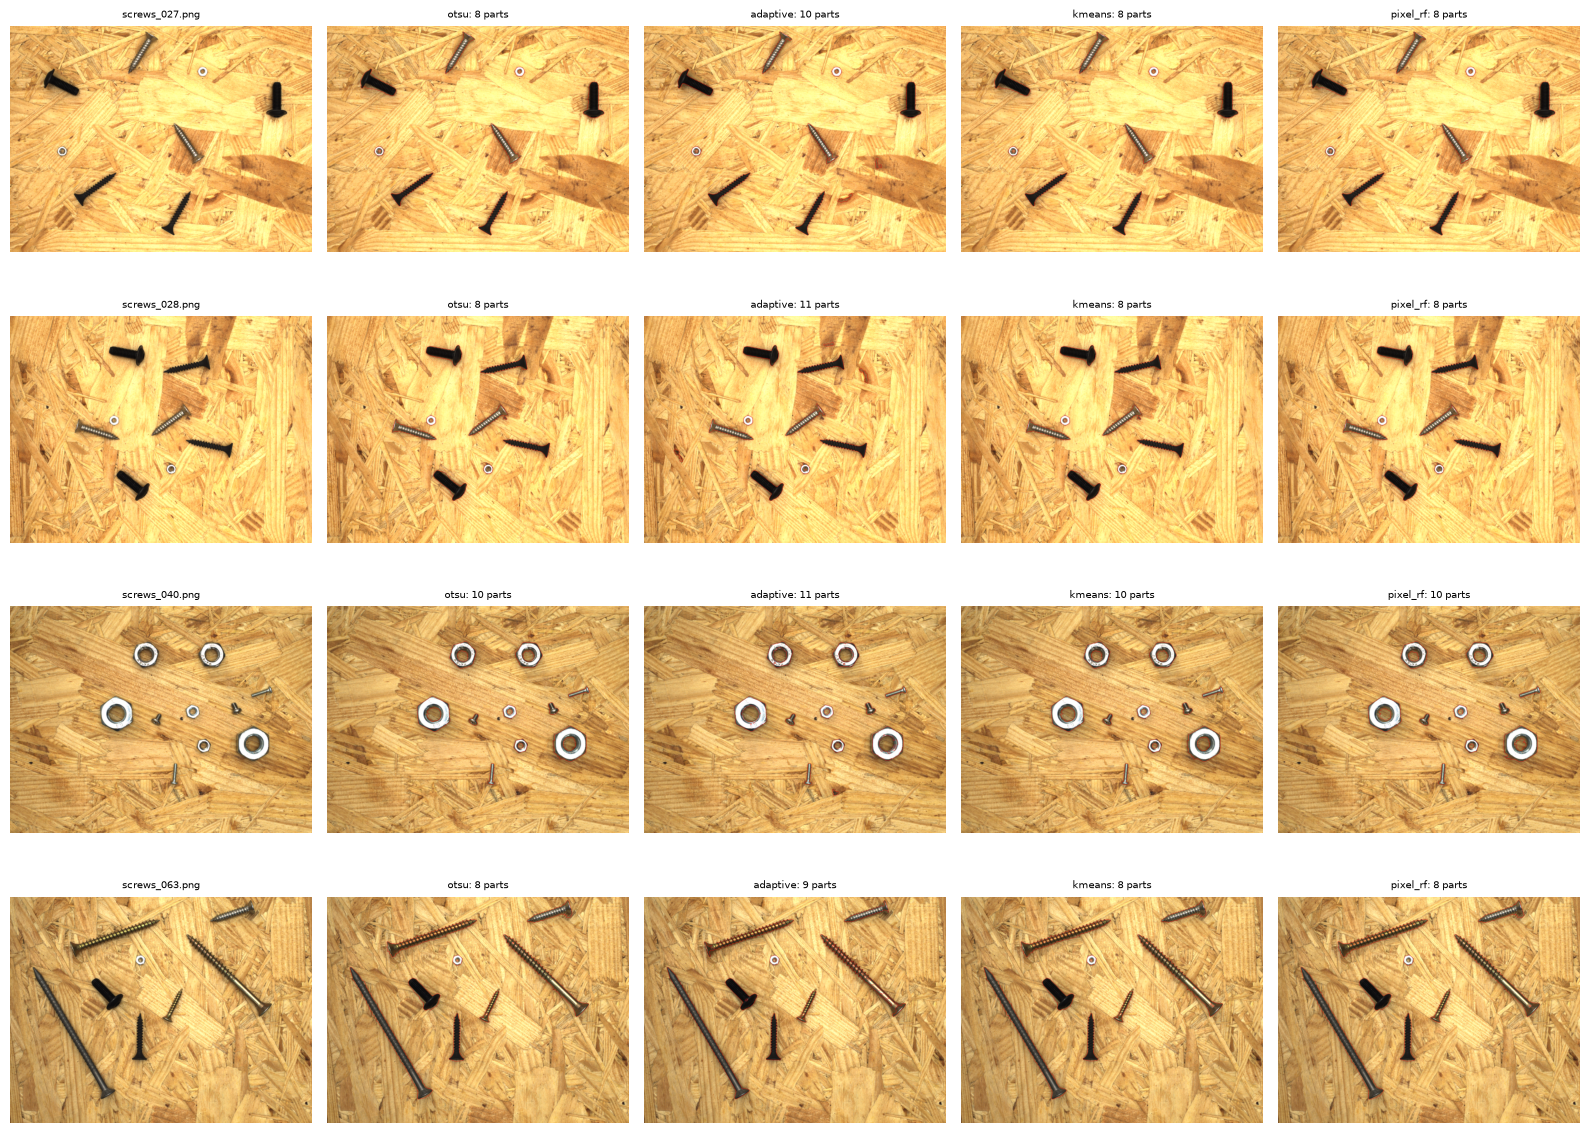

In [9]:
# qualitative comparison: contours of each method over the image
show = test_set[:4] or paths[:4]
assert show, "no images in inputs/"
fig, ax = plt.subplots(len(show), len(METHODS)+1, figsize=(3.2*(len(METHODS)+1), 3*len(show)), squeeze=False)
for r, p in enumerate(show):
    img = prep(p); ax[r,0].imshow(img); ax[r,0].set_title(p.name, fontsize=7)
    for c, (name, fn) in enumerate(METHODS.items(), 1):
        lab = cache.get((p.name, name), postprocess(fn(img)))
        ov = segmentation.mark_boundaries(img, lab, color=(1,0,0))
        ax[r,c].imshow(ov); ax[r,c].set_title(f"{name}: {lab.max()} parts", fontsize=7)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "qualitative.png", dpi=150); plt.show()

## 7. To discuss in the report (your own words)
- Which plane works best, and *why* (golden vs black vs silver parts)? Evidence: plane study table.
- What breaks a global threshold (stains, chips, highlights, thin threads, bores)?
- Touching parts: re-run with `SPLIT_TOUCHING = True`; compare merges/splits/IoU.
- Error types per method: false positives, merges, splits; are they acceptable for **counting**?
- Sensitivity to parameters (`MAX_SIDE`, `MIN_AREA_FRAC`, morphology radii), with a small ablation.
- Final decision: best method with statistics (mean ± std, per-image paired differences).